Spectrum of Cesium-137

In [136]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [ ]:
h_Cs = 243.17576721634862 
h_Na_1 = 197.22530992597498
h_Na_2 = 499.298182758717

E_Cs = 661.638 #keV
E_Na_1 = 511.006 #keV
E_Na_2 = 1274.511 #keV

E_err_Cs = 0.019 #keV
E_err_Na_1 = 0 #keV
E_err_Na_2 = 0.028 #keV

h_Cs_err = 0.1595702654960676
h_Na_err_1 = 0.4509864330864726
h_Na_err_2 = 3.7916435080428266


E = [E_Cs, E_Na_1, E_Na_2]
E_err = [E_err_Cs, E_err_Na_1, E_err_Na_2]
h_err = [h_Cs_err, h_Na_err_1, h_Na_err_2]
h = [h_Cs, h_Na_1, h_Na_2]

In [138]:
h_err_array = np.array(h_err)

h_inv_err = 1 / h_err_array
h_inv_err = list(h_inv_err)

In [139]:
def linear_model(x,a,b):
    y = a*x + b
    return y

In [140]:
spectrum = models.Model(linear_model)
fit_result = spectrum.fit(h, x=E, a=1, b=26, weights=h_inv_err)

print(fit_result.fit_report())

[[Model]]
    Model(linear_model)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 7
    # data points      = 3
    # variables        = 2
    chi-square         = 260.020798
    reduced chi-square = 260.020798
    Akaike info crit   = 17.3864480
    Bayesian info crit = 15.5836726
    R-squared          = 0.94468214
[[Variables]]
    a:  0.32892532 +/- 0.04530555 (13.77%) (init = 1)
    b:  26.0314761 +/- 29.3616072 (112.79%) (init = 26)
[[Correlations]] (unreported correlations are < 0.100)
    C(a, b) = -0.9966


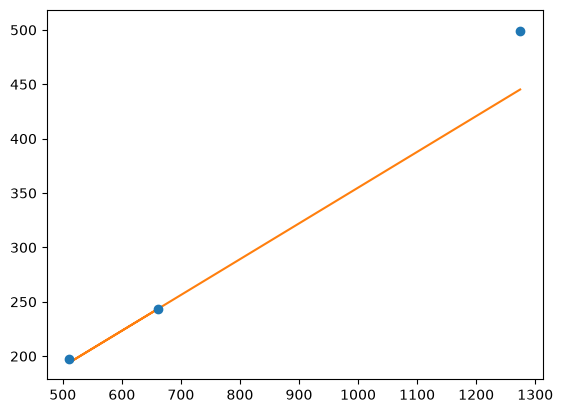

In [141]:
plt.errorbar(E,h,xerr=E_err,yerr=h_err, fmt='o')
plt.plot(E, fit_result.best_fit)
# plt.ylim(0,1000)
# plt.xlim(0, 2000)
plt.show()

In [149]:
a = fit_result.params["a"].value 
b = fit_result.params["b"].value 

a_err = fit_result.params["a"].stderr

print(f"a={a}")
print(f"a_err={a_err}")
print(f"b={b}")

a=0.3289253213202916
a_err=0.04530554546847939
b=26.031476080458457
